In [1]:
import dipole
import minimizing
import numpy as np
import matplotlib.pyplot as plt

In [14]:
bk_file = "/home/caaucasu/sidis_fit/data/bk_samplefrommvefit.dat"
BKinterpolator = dipole.BKDipole(bk_file)
init = [1.0, 1.0, 1.0, 1.0]
lbounds = [0.001, 0.001, 0.001, 0.001]
ubounds = [10.0, 100.0, 100.0, 10.0]
#init = [(lbounds[i] + ubounds[i])/2 for i in range(len(lbounds))]
print("init", init)
NrY = lambda yy,rr: BKinterpolator.ln_Nr(yy,rr)
y = 2.0 
r = np.logspace(-3, 2, 50)
minimizer = minimizing.MyMinimizer(NrY, y, r, init) #, lbounds = lbounds, ubounds = ubounds)
out = minimizer.fit_ls()

init [1.0, 1.0, 1.0, 1.0]


/home/caaucasu/sidis_fit/src/minimizing.py:25: RuntimeWarning: invalid value encountered in scalar power
  exponent = (((r**2 * Qs2) ** gamma)/4 * np.log( (1/(r*lambda_qcd)) + np.exp(1)*ec ) )** p
/home/caaucasu/sidis_fit/src/minimizing.py:25: RuntimeWarning: invalid value encountered in log
  exponent = (((r**2 * Qs2) ** gamma)/4 * np.log( (1/(r*lambda_qcd)) + np.exp(1)*ec ) )** p


In [15]:
fit_params = out.x
fit_func = minimizer.parametrization(fit_params[0], fit_params[1], fit_params[2], fit_params[3])
print("Fitted parameters:", fit_params)

Fitted parameters: [0.08704104 2.01246287 0.3526437  0.48595946]


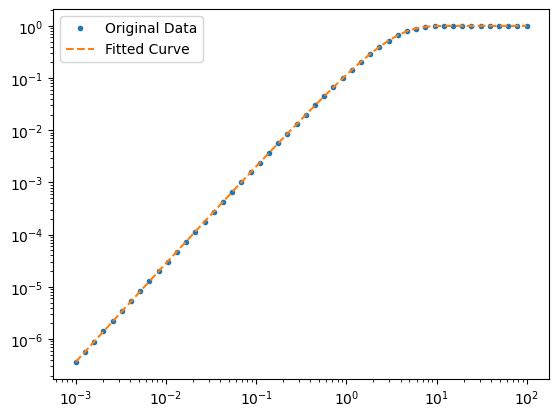

In [16]:
plt.plot(r, np.exp(NrY(y,r)), '.', label='Original Data')
plt.plot(r, np.exp(fit_func), label='Fitted Curve', linestyle='--')
plt.legend()
plt.xscale('log')
plt.yscale('log')
